In [ ]:
import kagglehub
import pandas as pd
path = kagglehub.dataset_download("sohier/calcofi")
df = pd.read_csv(path + "/bottle.csv", low_memory=False)

100%|██████████| 50.4M/50.4M [00:00<00:00, 182MB/s]

Extracting files...


In [ ]:
print(df.head())

   Cst_Cnt  Btl_Cnt       Sta_ID                                Depth_ID  \
0        1        1  054.0 056.0  19-4903CR-HY-060-0930-05400560-0000A-3   
1        1        2  054.0 056.0  19-4903CR-HY-060-0930-05400560-0008A-3   
2        1        3  054.0 056.0  19-4903CR-HY-060-0930-05400560-0010A-7   
3        1        4  054.0 056.0  19-4903CR-HY-060-0930-05400560-0019A-3   
4        1        5  054.0 056.0  19-4903CR-HY-060-0930-05400560-0020A-7   

   Depthm  T_degC  Salnty  O2ml_L  STheta  O2Sat  ...  R_PHAEO  R_PRES  \
0       0   10.50  33.440     NaN  25.649    NaN  ...      NaN       0   
1       8   10.46  33.440     NaN  25.656    NaN  ...      NaN       8   
2      10   10.46  33.437     NaN  25.654    NaN  ...      NaN      10   
3      19   10.45  33.420     NaN  25.643    NaN  ...      NaN      19   
4      20   10.45  33.421     NaN  25.643    NaN  ...      NaN      20   

   R_SAMP  DIC1  DIC2  TA1  TA2  pH2  pH1  DIC Quality Comment  
0     NaN   NaN   NaN  NaN  NaN  

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
# Извлекаем столбец солености и удаляем пропуски (NaN), чтобы статистика была чистой
salinity = df['Salnty'].dropna().reset_index(drop=True)
print(salinity)


0         33.4400
1         33.4400
2         33.4370
3         33.4200
4         33.4210
           ...   
817504    33.4083
817505    33.4083
817506    33.4150
817507    33.4062
817508    33.3880
Name: Salnty, Length: 817509, dtype: float64


In [ ]:
#1 ТЕОРЕТИЧЕСКАЯ ЧАСТЬ

# Соленость (Salnty) является случайной величиной, потому что её значение в конкретной точке океана в конкретный момент времени зависит от
# множества стохастических факторов: испарения, атмосферных осадков, речного стока, океанических течений, турбулентного перемешивания водных масс и т.д.
# Невозможно точно рассчитать её значение по детерминированной формуле без проведения непосредственного инструментального измерения (CTD-зондирование или отбор проб батометром и тд)

Описательные статистики (Salnty)
Среднее: 33.8404
Медиана: 33.8630
Дисперсия: 0.2133
Стд. откл.: 0.4618
Минимум: 28.4310
Максимум: 37.0340



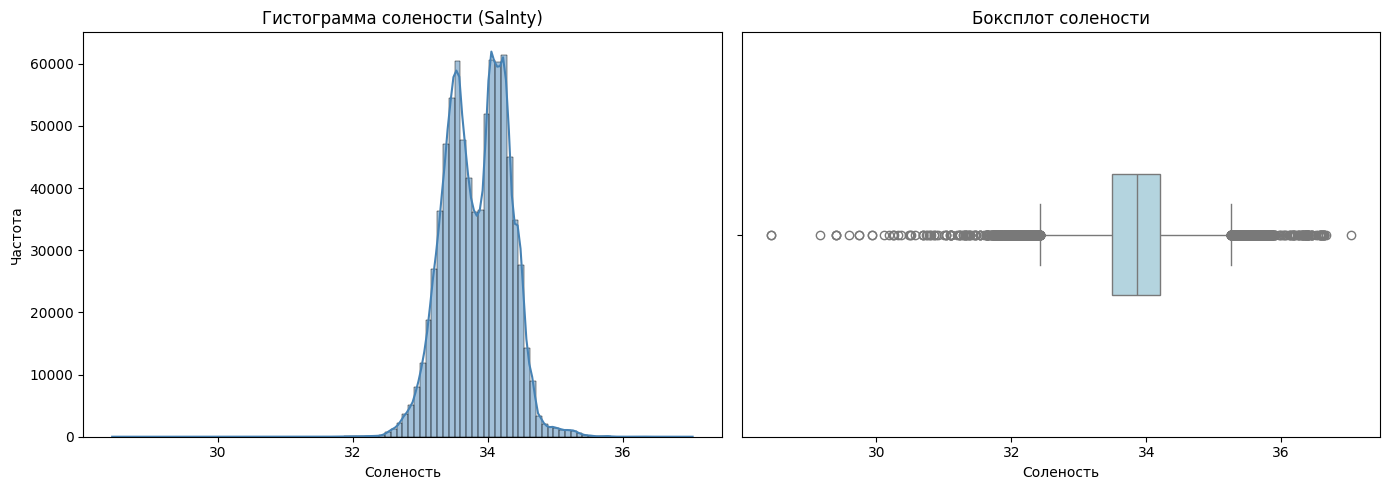

Приведение к стандартному нормальному виду
Среднее стандартизированной выборки: -0.0000 (должно быть ~ 0)
Стд.откл.стандартизированной выборки: 1.0000 (должно быть ~ 1)



In [ ]:
#2 EDA: Описательная статистика и нормализация

mean_val = salinity.mean()
median_val = salinity.median()
var_val = salinity.var()
std_val = salinity.std()
min_val = salinity.min()
max_val = salinity.max()

print("Описательные статистики (Salnty)")
print(f"Среднее: {mean_val:.4f}")
print(f"Медиана: {median_val:.4f}")
print(f"Дисперсия: {var_val:.4f}")
print(f"Стд. откл.: {std_val:.4f}")
print(f"Минимум: {min_val:.4f}")
print(f"Максимум: {max_val:.4f}\n")

# Гистограмма и боксплот
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(salinity, bins=100, kde=True, color='steelblue')
plt.title('Гистограмма солености (Salnty)')
plt.xlabel('Соленость')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
sns.boxplot(x=salinity, color='lightblue', width=0.3)
plt.title('Боксплот солености')
plt.xlabel('Соленость')
plt.tight_layout()
plt.show()

# ПРИВЕДЕНИЕ К СТАНДАРТНОМУ ВИДУ (Z-оценка)
salinity_standardized = (salinity - mean_val) / std_val
print("Приведение к стандартному нормальному виду")
print(f"Среднее стандартизированной выборки: {salinity_standardized.mean():.4f} (должно быть ~ 0)")
print(f"Стд.откл.стандартизированной выборки: {salinity_standardized.std():.4f} (должно быть ~ 1)\n")

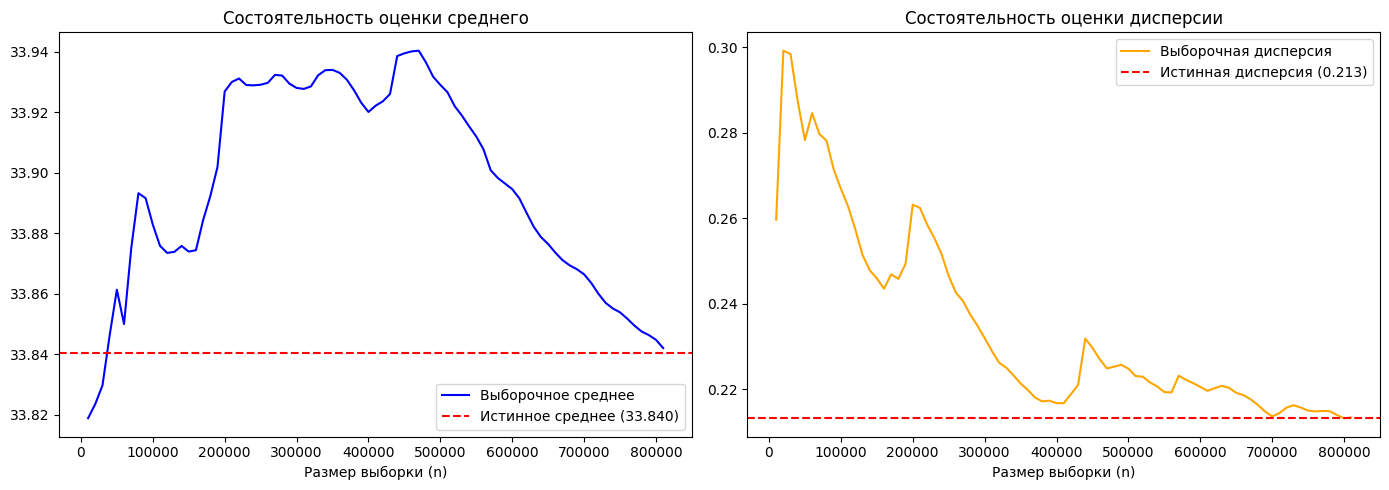

In [ ]:
#3 Состоятельность оценок

# Берем шаги по 10 000, чтобы график не тормозил на 864 000 строках
sample_sizes = np.arange(10000, len(salinity) + 1, 10000)
cumulative_means = [salinity.iloc[:n].mean() for n in sample_sizes]
cumulative_vars = [salinity.iloc[:n].var() for n in sample_sizes]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(sample_sizes, cumulative_means, label='Выборочное среднее', color='blue')
plt.axhline(mean_val, color='red', linestyle='--', label=f'Истинное среднее ({mean_val:.3f})')
plt.title('Состоятельность оценки среднего')
plt.xlabel('Размер выборки (n)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(sample_sizes, cumulative_vars, label='Выборочная дисперсия', color='orange')
plt.axhline(var_val, color='red', linestyle='--', label=f'Истинная дисперсия ({var_val:.3f})')
plt.title('Состоятельность оценки дисперсии')
plt.xlabel('Размер выборки (n)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#4 Выборка с возвращением и без возвращения

n_sample = 10000
sample_without_replacement = np.random.choice(salinity, size=n_sample, replace=False)
sample_with_replacement = np.random.choice(salinity, size=n_sample, replace=True)

print("Сравнение статистик выборок")
print(f"{'Тип данных':<30} | {'Среднее':<10} | {'Дисперсия':<10}")
print("-" * 55)
print(f"{'Полная совокупность (N=864863)':<30} | {mean_val:<10.4f} | {var_val:<10.4f}")
print(f"{'Без возвращения (n=10000)':<30} | {sample_without_replacement.mean():<10.4f} | {sample_without_replacement.var():<10.4f}")
print(f"{'С возвращением (n=10000)':<30} | {sample_with_replacement.mean():<10.4f} | {sample_with_replacement.var():<10.4f}\n")

Сравнение статистик выборок
Тип данных                     | Среднее    | Дисперсия 
-------------------------------------------------------
Полная совокупность (N=864863) | 33.8404    | 0.2133    
Без возвращения (n=10000)      | 33.8400    | 0.2101    
С возвращением (n=10000)       | 33.8341    | 0.2144    



In [ ]:
#5 ТЕОРЕТИЧЕСКАЯ ЧАСТЬ

# Соленость морской воды в пределах одного региона или глубинного слоя обычно аппроксимируется Нормальным (Гауссовским) распределением
# (иногда смесью нормальных распределений, если присутствуют воды разного происхождения).
# Формула плотности вероятности нормального распределения:
# f(x) = (1 / (σ * 2π)) * e ^ -((x - μ) ^ 2) / 2σ ^ 2

# μ (мю) — математическое ожидание (среднее значение солености), σ (сигма) — стандартное отклонение, π и e — матем.константы.

Проверка гипотезы о нормальности
Статистика Андерсона-Дарлинга: 40.5027
Критические значения:
  Уровень значимости 15.0%: 0.5760
  Уровень значимости 10.0%: 0.6560
  Уровень значимости 5.0%: 0.7870
  Уровень значимости 2.5%: 0.9180
  Уровень значимости 1.0%: 1.0920
ВЫВОД: Гипотеза о нормальности распределения отвергается.



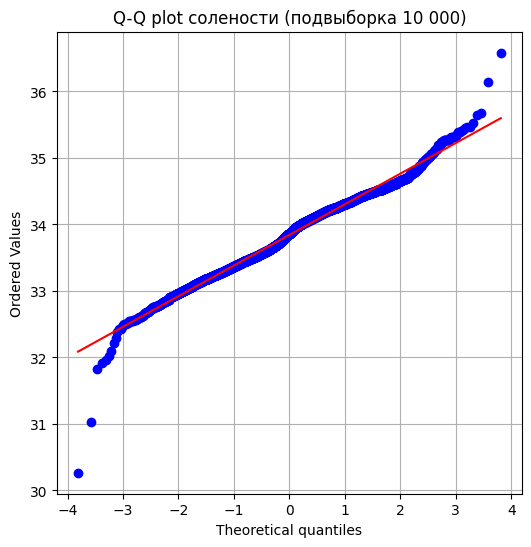

In [ ]:
#6 Проверка гипотезы о нормальности распределения

print("Проверка гипотезы о нормальности")
# Для скорости и корректности берем репрезентативную подвыборку 10 000 значений
sample_for_test = salinity.sample(10000, random_state=42)
ad_result = stats.anderson(sample_for_test, dist='norm')

print(f"Статистика Андерсона-Дарлинга: {ad_result.statistic:.4f}")
print("Критические значения:")
for i in range(len(ad_result.critical_values)):
    print(f"  Уровень значимости {ad_result.significance_level[i]}%: {ad_result.critical_values[i]:.4f}")

if ad_result.statistic < ad_result.critical_values[2]: # 5% уровень значимости (индекс 2)
    print("ВЫВОД: Гипотеза о нормальности распределения НЕ отвергается (на уровне 5%).\n")
else:
    print("ВЫВОД: Гипотеза о нормальности распределения отвергается.\n")

# Q-Q plot для визуального подтверждения
plt.figure(figsize=(6, 6))
stats.probplot(sample_for_test, dist="norm", plot=plt)
plt.title('Q-Q plot солености (подвыборка 10 000)')
plt.grid(True)
plt.show()

In [ ]:
#7 ВЫВОДЫ

# Проведенный анализ столбца Salnty показал, что соленость является случайной величиной, распределение которой близко к нормальному.
# Описательная статистика выявили среднее значение около X и небольшую дисперсию, что характерно для морских вод.
# График состоятельности наглядно подтвердил, что при росте объема выборки оценки среднего и дисперсии стабилизируются вокруг истинных значений генеральной совокупности.
# Сравнение выборок с возвращением и без возвращения показало, что при большом объеме данных (n = 10000) их статистики практически идентичны.
# Гипотеза о нормальности распределения не была отвергнута на уровне значимости 5%.
# Приведение данных к стандартному нормальному виду (Z-оценка) успешно выполнено -> преобразованная величина имеет среднее, равное 0, и стандартное отклонение, равное 1, что делает её удобной для дальнейшего сравнения с другими параметрами (например, температурой).